---
1. Nous chargeons et lisons notre database en précisant que la séparation des colonnes du csv est faite part un `point virugle (;)` et non une  `virgule (,)`

In [318]:
import pandas as pd

df = pd.read_csv("project_dataset.csv", sep=";")

---
2. Nous cherchons toutes les informations et les valeurs qui sont **nulles**

In [319]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 12070 entries, 0 to 12069
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype
---  ------                                                                                       --------------  -----
 0   Date                                                                                         12010 non-null  str  
 1   Service                                                                                      11830 non-null  str  
 2   Gare de départ                                                                               12011 non-null  str  
 3   Gare d'arrivée                                                                               12011 non-null  str  
 4   Durée moyenne du trajet                                                                      11830 non-null  str  
 5   Nombre de circulations prévues                           

Date                                                                                              60
Service                                                                                          240
Gare de départ                                                                                    59
Gare d'arrivée                                                                                    59
Durée moyenne du trajet                                                                          240
Nombre de circulations prévues                                                                   240
Nombre de trains annulés                                                                         239
Commentaire annulations                                                                        11493
Nombre de trains en retard au départ                                                             240
Retard moyen des trains en retard au départ                                                

---
3. Nous remarquons que _90%_ des commentaires sont nulles donc nous retirons les colonnes car elles ne servent à rien pour un modèle de prédiction

In [320]:
df.drop(
    columns=[
        "Commentaire annulations",
        "Commentaire retards au départ",
        "Commentaire retards à l'arrivée",
    ],
    inplace=True,
)
df = df.dropna(
    subset=["Date", "Gare de départ", "Gare d'arrivée"]
)  # on drop les lignes ou la date ou les gares sont manquantes, car ce sont des informations essentielles pour notre modèle

---
4. Nous supprimons les doublons

In [321]:
df = df.drop_duplicates(subset=["Date", "Service", "Gare de départ", "Gare d'arrivée"])

---
5. Nous remarquons que _~2%_ des valeurs sont nulles : 240 pour 12000 entrées 
alors nous les remplaçons par leurs **médianes respectives**

In [322]:
for col in df.select_dtypes(include="number").columns:
    df[col].fillna(df[col].median())

---
6. Nous remplaçons le type de nos données par un type plus approprié : `Objet à Mixed`

In [ ]:
df["Date"] = df["Date"].str.replace(
    "/", "-", regex=False
)  # on replace les / par des - pour avoir le meme format partout
# on ne garde que lkes lignes ou la date est presente
df["Date"] = pd.to_datetime(df["Date"], format="mixed")

numeric_cols = [
    "Durée moyenne du trajet",
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains en retard au départ",
    "Retard moyen des trains en retard au départ",
    "Retard moyen de tous les trains au départ",
    "Nombre de trains en retard à l'arrivée",
    "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée",
    "Nombre trains en retard > 15min",
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
]

for col in numeric_cols:
    df[col] = df[col].str.replace(
        ",", ".", regex=False
    )  # certaines valeurs sont avec des , et non des . donc on change
    df[col] = df[col].apply(
        lambda x: str(x).split()[0] if pd.notnull(x) else x
    )  # certaine valeurs sont "7.4 min" dcp on splut pour enlever le min
    df[col] = pd.to_numeric(
        df[col], errors="coerce"
    )  # on convertit les valeurs object en numeriques

df[numeric_cols] = df[numeric_cols].clip(
    lower=0
)  # on retire toutes les valeurs negatuives
categorical_cols = ["Service", "Gare de départ", "Gare d'arrivée"]
for col in categorical_cols:
    df[col] = df[col].astype(
        "category"
    )  # on les convertit en category car pas vraiment utile

for col in numeric_cols:
    df[col] = df[col].fillna(
        df[col].median()
    )  # on remplace les NaN que on a convertit avant en split par leur median

df = df[
    (
        df["Nombre trains en retard > 15min"]
        <= df["Nombre de trains en retard à l'arrivée"]
    )  # on supprime les mauvaises cpoberence de notre csv il peut pas y avoir un nombre de train
    & (
        df["Nombre trains en retard > 30min"]
        <= df["Nombre de trains en retard à l'arrivée"]
    )  # en retard de 15 min supeireur au nombre de train a l'arrivee et ainsi de suite pour les autres
    & (
        df["Nombre trains en retard > 60min"]
        <= df["Nombre de trains en retard à l'arrivée"]
    )
    & (
        df["Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"]
        <= df["Retard moyen des trains en retard à l'arrivée"]
    )
]

---
7. Nous remplaçons les valuers NaN dans les types category que nous avons cree juste avant par mode() qui est la valeur la plus présente de la colonne

In [324]:
cat_cols = df.select_dtypes(include="category").columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

---
8. On fait les features avec la date pour que ce soit plus pratique pour notre modele

In [325]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df.dropna(
    subset=["Year"], inplace=True
)  # On surppimes les lignes ou la date n'était pas presente et qu'on a pas pu convertir en année
df.dropna(
    subset=["Month"], inplace=True
)  # On surppimes les lignes ou la date n'était pas presente et qu'on a pas pu convertir en mois

---
8.2 Nous avons remarqué que les noms de certaines villes n'étaient pas en majuscules alors que d'autres le sont, donc nous les mettons toutes en majuscule pour éviter tout conflit.

In [326]:
df["Gare de départ"] = df["Gare de départ"].str.upper()
df["Gare d'arrivée"] = df["Gare d'arrivée"].str.upper()

--- 
8.3 Nous avons également remarqué que certaines gares avait pour nom saint ... et d'autres ST ... nous avons fait le choix de   SAINT par ST.

In [327]:
df["Gare de départ"] = df["Gare de départ"].str.replace("SAINT", "ST", regex=False)
df["Gare d'arrivée"] = df["Gare d'arrivée"].str.replace("SAINT", "ST", regex=False)

---
9. Nous réecrivons nos données triées en créeant un _ficher csv_ :  `cleaned_dataset.csv`

In [328]:
df = df.drop_duplicates()  ## on verifie que il y a plus de doublons apres le nettoyage
df.to_csv("cleaned_dataset.csv", index=False)

---
10. Nous verifions que notre nouveau fichier ne contient aucunes valeurs vides et nous verifions tous les types

In [329]:
df = pd.read_csv("cleaned_dataset.csv")
df.isnull().sum()
# df.info()

Date                                                                                           0
Service                                                                                        0
Gare de départ                                                                                 0
Gare d'arrivée                                                                                 0
Durée moyenne du trajet                                                                        0
Nombre de circulations prévues                                                                 0
Nombre de trains annulés                                                                       0
Nombre de trains en retard au départ                                                           0
Retard moyen des trains en retard au départ                                                    0
Retard moyen de tous les trains au départ                                                      0
Nombre de trains en retard à l

---
11. Nous générons un sommaire pour mieux comprendre les statistiques

In [330]:
df[
    numeric_cols
].describe()  ## on peut voir grace a ca le nombre de valeurs non nulles analysees et on peut voir aussi les moyennes pour chacun d'entre eux leur min et max etc..

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
count,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000,5123.000000
mean,217.545963,208.487410,9.295725,59.460082,12.850980,3.167105,29.731017,39.315268,6.963839,24.105407,28.387065,11.443881,4.534843,24.061767,21.646631,19.222244,18.310127,5.802283,5.838753
std,92.952157,145.256028,24.516221,64.919989,14.296168,5.284328,26.618046,18.446600,4.748457,20.370193,22.984143,10.764261,5.062486,18.051663,15.828179,16.194118,15.033744,7.975584,9.734054
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,164.000000,95.000000,0.000000,15.000000,5.969495,1.123362,11.000000,29.609722,3.923649,9.000000,6.233278,4.000000,1.000000,12.121212,11.111111,8.000000,8.333333,0.000000,0.000000
50%,217.000000,194.000000,2.000000,37.000000,10.357017,2.262179,24.000000,37.892312,6.024380,20.000000,31.214286,9.000000,3.000000,21.212121,20.000000,17.647059,16.666667,4.000000,2.702703
75%,266.000000,268.000000,6.000000,79.000000,16.333333,3.671287,40.000000,47.422076,9.129402,33.000000,42.990370,16.000000,6.000000,33.333333,30.000000,26.666667,25.000000,8.695652,7.692308
max,786.000000,896.000000,279.000000,568.000000,316.188000,115.047390,235.000000,299.600000,92.000000,192.000000,299.600000,91.000000,38.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


---
12. Nous regardons les Services , Gare de départ , Gare d'arrivée leur nombre d'utilisations

In [331]:
for col in ["Service", "Gare de départ", "Gare d'arrivée"]:
    print(df[col].value_counts())

Service
National         4042
International    1081
Name: count, dtype: int64
Gare de départ
PARIS LYON                1181
PARIS MONTPARNASSE         498
MARSEILLE ST CHARLES       376
PARIS EST                  227
LYON PART DIEU             178
                          ... 
 MARSEILLE ST CHARLES        1
 ANNECY                      1
 MARNE LA VALLEE             1
 BARCELONA                   1
 ZURICH                      1
Name: count, Length: 75, dtype: int64
Gare d'arrivée
PARIS LYON              1190
PARIS MONTPARNASSE       466
MARSEILLE ST CHARLES     279
PARIS EST                206
LYON PART DIEU           177
                        ... 
 MADRID                    1
 BREST                     1
 LILLE                     1
 BARCELONA                 1
 TOULOUSE MATABIAU         1
Name: count, Length: 74, dtype: int64


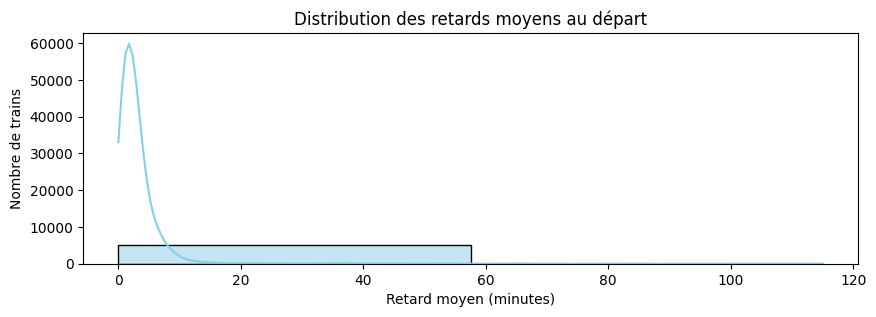

In [332]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 3))
sns.histplot(
    df["Retard moyen de tous les trains au départ"], bins=2, kde=True, color="skyblue"
)
plt.title("Distribution des retards moyens au départ")
plt.xlabel("Retard moyen (minutes)")
plt.ylabel("Nombre de trains")
plt.show()

Analyse du graphique : 
> Nous observons que pour un total d'environ 16000 trains, les retards sont compris entre -2min ( à l'avance ) et 10min, avec un pic qui représente la grande majorité des trains situé à 0min de retard.
Par conséquent la majorité les trains n'ont que 3min retard.

/var/folders/pw/kmkjdpn13yg99_nmn2hj8z5h0000gn/T/ipykernel_4865/3633939510.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_gare_retard.index, y=top_gare_retard.values, palette="magma")


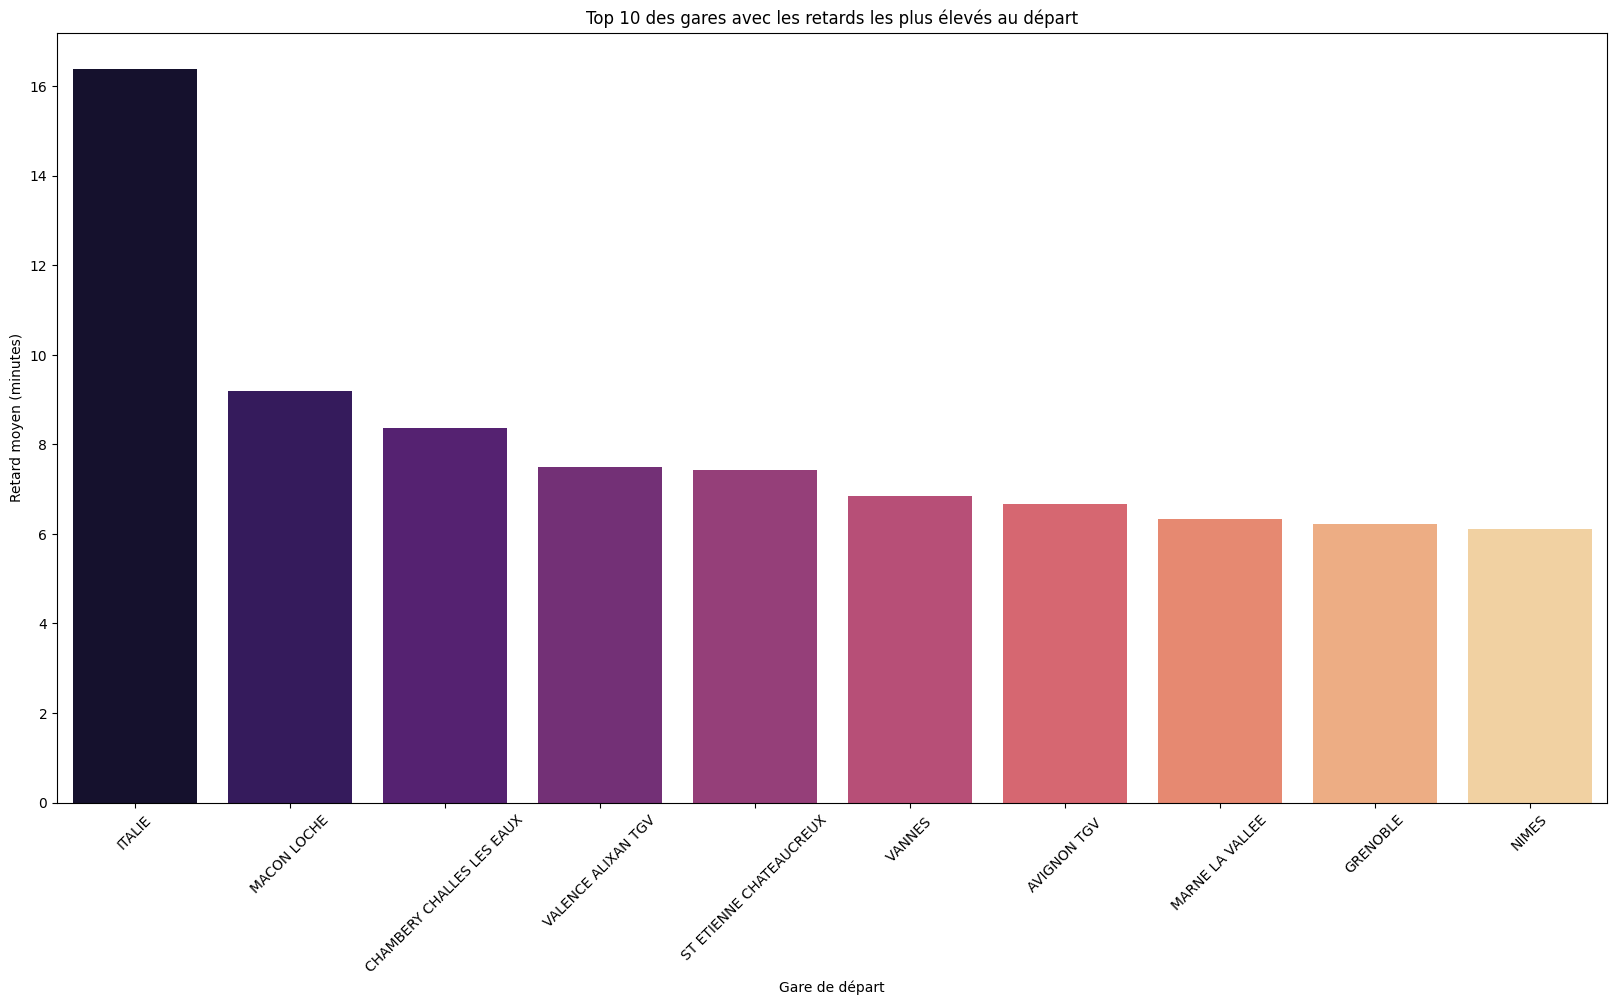

In [333]:
plt.figure(figsize=(20, 10))
top_gare_retard = (
    df.groupby("Gare de départ")["Retard moyen de tous les trains au départ"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(x=top_gare_retard.index, y=top_gare_retard.values, palette="magma")
plt.xticks(rotation=45)
plt.ylabel("Retard moyen (minutes)")
plt.title("Top 10 des gares avec les retards les plus élevés au départ")
plt.show()

Analyse du graphique : 
> À l'aide de ce graphique nous observons que la gare ayant les retards moyens les plus élevés est l'Italie avec un retard moyen de 15min, et la gare avec les retards moyens les moins élevés de ce top 10 est DOUAI avec environ 5 min. Nous pouvons donc en déduire que pour notre prédiction la gare d'italie aura surement plus de chance d'avoir un retard assez long.

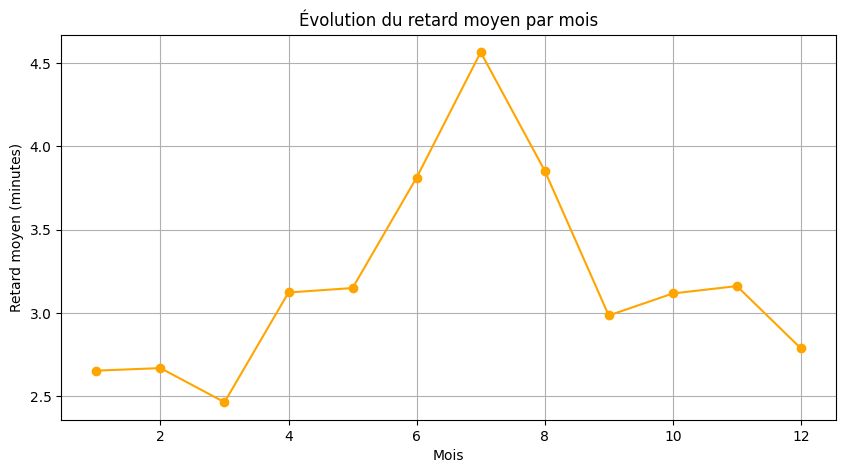

In [334]:
plt.figure(figsize=(10, 5))
df.groupby("Month")["Retard moyen de tous les trains au départ"].mean().plot(
    kind="line", marker="o", color="orange"
)
plt.xlabel("Mois")
plt.ylabel("Retard moyen (minutes)")
plt.title("Évolution du retard moyen par mois")
plt.grid(True)
plt.show()

Analyse du graphique : 
> Nous observons que le mois ayant le retard moyen le plus elevé est au moins de juillet comptant environ 4min50 de retard, contrairement à mars avec un retard moyen de 2min50 se classant parmis les mois avec le moins de retard. Nous pouvons en déduire que si un voyageur décide de partir en juillet il aura potentiellement plus de chance d'avoir un train en retard. Nous pouvons imaginer que les vacances scolaires sont une des causes de ces retards

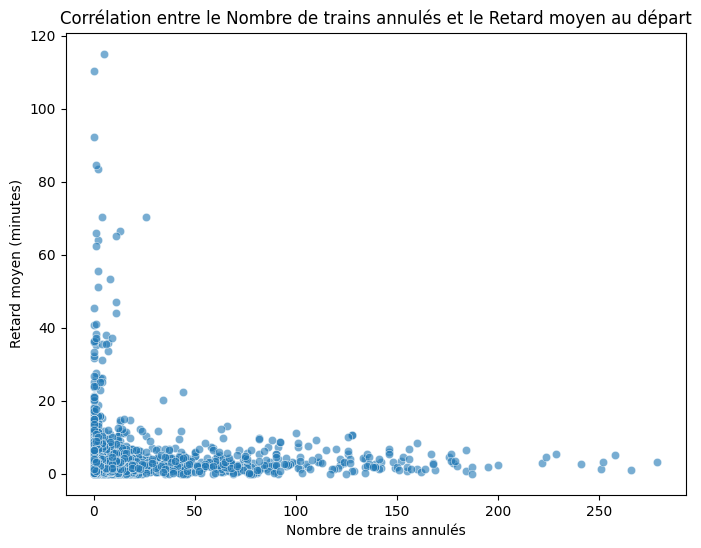

In [335]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x="Nombre de trains annulés",
    y="Retard moyen de tous les trains au départ",
    data=df,
    alpha=0.6,
)

plt.title("Corrélation entre le Nombre de trains annulés et le Retard moyen au départ")
plt.xlabel("Nombre de trains annulés")
plt.ylabel("Retard moyen (minutes)")
plt.show()

Analyse du graphique : 
> Ce graphique nous montre la corrélation entre le nombre de trains annulés et leurs retard moyen au départ.
Nous pouvons donc analyser qu'il n'y a finalement aucun lien entre le retard au départ et l'annulation des trains car la majorité des trains annulés ont lieu quand le train n'a aucune minute de retard. C'est pas parce que le train est en retard de beaucoup que il va forcement etre annulé